In [1]:

from typing import TypedDict
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
import os

load_dotenv()

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

llm = ChatOpenAI(
    model="Qwen/Qwen3.5-4B",
    base_url="https://prod-vllm-2.kriyam.ai/v1",
    api_key=os.getenv("VLM_API_TOKEN"),
    temperature=0,
    timeout=120,
    max_retries=2,
    max_tokens=4096,
    extra_body={"chat_template_kwargs": {"enable_thinking": False}}
)

class PropertyRequirements(BaseModel):
    property_type: str
    bhk: str | None
    city: str
    preferred_areas: list[str]
    budget_min: int | None
    budget_max: int | None
    amenities: list[str]
    connectivity_preferences: list[str]
    other_preferences: list[str]


class ResearchTask(BaseModel):
    area: str | None = None
    objective: str
    information_to_find: list[str]
    initial_search_queries: list[str]
    priority: str


class PlannerOutput(BaseModel):
    intent: str
    requirements: PropertyRequirements
    property_fields_to_collect: list[str]
    research_tasks: list[ResearchTask]
    research_strategy: str
    evaluation_criteria: list[str]


class PlannerState(TypedDict):
    user_query: str
    planner_output: dict


In [5]:

planner_llm = llm.with_structured_output(PlannerOutput)

def planner_agent(state: PlannerState):

    prompt = f"""
    You are a real estate research planning agent.

    Understand the customer's request and create a structured
    research plan for the next Research Agent.

    Customer Query:
    {state['user_query']}

    Your responsibilities:

    1. Identify the customer's intent.
    2. Extract all property requirements.
    3. Identify preferred locations separately.
    4. Identify mandatory and optional requirements.
    5. Create 3 research tasks based on locations and other
       independent research requirements.
    6. For every task, specify:
       - Research objective
       - Information to find
       - Initial Tavily search query suggestions
       - Priority
    7. Specify which fields the Research Agent must collect
       for every property.
    8. Define evaluation criteria for the Evaluator Agent.

    Important instructions:

    - Do not invent missing customer requirements.
    - Use null for unknown budget limits or BHK.
    - Do not create unnecessary duplicate tasks.
    - Create separate property discovery tasks for
      different preferred locations.
    - Include connectivity research when requested.
    - Do not perform actual web searches.
    - The Research Agent will decide whether additional
      searches are needed after examining search results.

    Return a complete structured research plan.
    """

    result = planner_llm.invoke(prompt)

    output = result.model_dump()

    for i, task in enumerate(output["research_tasks"], start=1):
        task["task_id"] = f"T{i}"

    return {"planner_output": output}


In [6]:
builder = StateGraph(PlannerState)

builder.add_node("planner", planner_agent)

builder.add_edge(START, "planner")
builder.add_edge("planner", END)

planner_graph = builder.compile()

In [7]:
query = """
Find a 2 BHK apartment in Pune near Hinjewadi or Wakad.
My budget is 60-75 lakh.
I need covered parking, a gym and good connectivity to IT parks.
"""

result = planner_graph.invoke({
    "user_query": query
})

print(result["planner_output"])

{'intent': 'The customer is seeking to purchase a residential property, specifically a 2 BHK apartment, in the Pune metropolitan area with a focus on the Hinjewadi and Wakad zones.', 'requirements': {'property_type': '2 BHK Apartment', 'bhk': '2', 'city': 'Pune', 'preferred_areas': ['Hinjewadi', 'Wakad'], 'budget_min': 6000000, 'budget_max': 7500000, 'amenities': ['Covered Parking', 'Gym'], 'connectivity_preferences': ['Good connectivity to IT parks'], 'other_preferences': []}, 'property_fields_to_collect': ['Property Name', 'Developer Name', 'Location (Exact Address)', 'BHK Configuration', 'Price per Sq. Ft.', 'Total Area (Built-up)', 'Total Price', 'Availability Status (Ready/Under Construction)', 'Completion Date', 'Amenities List', 'Connectivity Details (Distance to IT Parks)', 'Parking Details (Covered/Uncovered, Ratio)', 'Contact Information'], 'research_tasks': [{'area': 'Hinjewadi', 'objective': 'Identify available 2 BHK apartments within the 60-75 lakh budget in Hinjewadi that

In [36]:

import os
import operator
from typing import TypedDict, Annotated, Optional

from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langchain_groq import ChatGroq
from langchain_tavily import TavilySearch
from langchain_core.messages import SystemMessage, HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send


load_dotenv()

# llm = ChatGroq(model=os.getenv("GROQ_MODEL", "llama-3.3-70b-versatile"), temperature=0)
llm = ChatOpenAI(
    model="Qwen/Qwen3.5-4B",
    base_url="https://prod-vllm-2.kriyam.ai/v1",
    api_key=os.getenv("VLM_API_TOKEN"),
    temperature=0,
    timeout=120,
    max_retries=2,
    max_tokens=4096,
    extra_body={"chat_template_kwargs": {"enable_thinking": False}}
)

tavily = TavilySearch(max_results=3, search_depth="basic")


# -----------------------------
# 1. Structured Output
# -----------------------------

from pydantic import BaseModel, Field, model_validator
from typing import Optional

class PropertyFinding(BaseModel):
    property_name: Optional[str] = None
    location: Optional[str] = None
    price: Optional[str] = None
    bhk: Optional[str] = None
    area_sqft: Optional[str] = None
    amenities: list[str] = Field(default_factory=list)
    connectivity: list[str] = Field(default_factory=list)
    availability: Optional[str] = None
    source_url: Optional[str] = None
    evidence: Optional[str] = None
    missing_information: list[str] = Field(default_factory=list)

    @model_validator(mode="before")
    @classmethod
    def normalize_null_lists(cls, values):
        if isinstance(values, dict):
            for field in ["amenities", "connectivity", "missing_information"]:
                if values.get(field) is None:
                    values[field] = []
        return values



class ResearchOutput(BaseModel):
    properties: list[PropertyFinding] = Field(default_factory=list)
    location_information: list[str] = Field(default_factory=list)
    important_findings: list[str] = Field(default_factory=list)
    missing_information: list[str] = Field(default_factory=list)


# -----------------------------
# 2. LangGraph State
# -----------------------------

class ResearchState(TypedDict, total=False):
    user_query: str
    planner_output: dict
    task: dict
    worker_findings: Annotated[list[dict], operator.add]
    aggregated_research: dict


# -----------------------------
# 3. Tavily Search
# -----------------------------

def tavily_search(query: str) -> list[dict]:

    response = tavily.invoke({"query": query})

    results = response.get("results", []) if isinstance(response, dict) else response

    return [
        {
            "title": item.get("title", ""),
            "url": item.get("url", ""),
            "content": item.get("content", ""),
            "score": item.get("score")
        }
        for item in results or []
    ]


# -----------------------------
# 4. Research Worker
# -----------------------------

def research_worker(state: ResearchState) -> dict:

    task = state["task"]
    requirements = state["planner_output"]["requirements"]

    queries = task.get("initial_search_queries", [])[:5]

    raw_results = []

    for query in queries:
        results = tavily_search(query)
        raw_results.extend(results)

    # Deduplicate search results
    unique_results = {
        item["url"]: item
        for item in raw_results
        if item.get("url")
    }

    # raw_results = list(unique_results.values())
    raw_results = list(unique_results.values())

    raw_results = [
        {
            "title": r["title"],
            "url": r["url"],
            "content": r["content"][:1000]
        }
        for r in raw_results
    ]


    

    if not raw_results:
        return {
            "worker_findings": [{
                "task_id": task["task_id"],
                "objective": task["objective"],
                "properties": [],
                "missing_information": ["No search results retrieved"],
                "search_queries_used": queries
            }]
        }

    extractor = llm.with_structured_output(ResearchOutput)

    extracted = extractor.invoke([
        SystemMessage(content="""
You are a real estate research agent.

Extract property information only from the provided search results.

Rules:
1. Never invent property information.
2. Use null for missing scalar values.
3. For amenities, connectivity and missing_information,
   ALWAYS return an array.
4. If no amenities are mentioned, return [].
5. If no connectivity information is mentioned, return [].
6. If no missing information exists, return [].
7. Preserve original source URLs.
8. Distinguish verified information from unverified claims.
"""),
        HumanMessage(content=f"""
        CUSTOMER REQUIREMENTS:
        {requirements}

        CURRENT RESEARCH TASK:
        {task}

        TAVILY SEARCH RESULTS:
        {raw_results}

        Extract the relevant findings for this task.
        """)
    ])

    return {
        "worker_findings": [{
            "task_id": task["task_id"],
            "objective": task["objective"],
            "area": task.get("area"),
            "properties": [
                item.model_dump()
                for item in extracted.properties
            ],
            "location_information": extracted.location_information,
            "important_findings": extracted.important_findings,
            "missing_information": extracted.missing_information,
            "search_queries_used": queries
        }]
    }


# -----------------------------
# 5. Fan-out
# -----------------------------

def dispatch_workers(state: ResearchState):

    tasks = state["planner_output"]["research_tasks"]

    return [
        Send(
            "research_worker",
            {
                "user_query": state["user_query"],
                "planner_output": state["planner_output"],
                "task": task
            }
        )
        for task in tasks
    ]


# -----------------------------
# 6. Aggregate Worker Results
# -----------------------------

def aggregate_results(state: ResearchState) -> dict:

    worker_findings = state.get("worker_findings", [])

    all_properties = {}

    for worker in worker_findings:
        for prop in worker.get("properties", []):

            url = prop.get("source_url")

            if url:
                all_properties[url] = prop

    return {
        "aggregated_research": {
            "user_query": state["user_query"],
            "planner_output": state["planner_output"],
            "total_workers": len(worker_findings),
            "worker_findings": worker_findings,
            "all_properties": list(all_properties.values())
        }
    }


# -----------------------------
# 7. Build Research Graph
# -----------------------------

builder = StateGraph(ResearchState)

builder.add_node("research_worker", research_worker)
builder.add_node("aggregate_results", aggregate_results)

builder.add_conditional_edges(
    START,
    dispatch_workers,
    ["research_worker"]
)

builder.add_edge("research_worker", "aggregate_results")
builder.add_edge("aggregate_results", END)

research_graph = builder.compile()


# -----------------------------
# 8. Execute Research Agent
# -----------------------------

def run_research(user_query: str, planner_output: dict):

    result = research_graph.invoke({
        "user_query": user_query,
        "planner_output": planner_output,
        "worker_findings": []
    })

    return result["aggregated_research"]


In [37]:
planner_result = planner_graph.invoke({
    "user_query": query
})

research_result = run_research(
    user_query=query,
    planner_output=planner_result["planner_output"]
)

print(research_result)

{'user_query': '\nFind a 2 BHK apartment in Pune near Hinjewadi or Wakad.\nMy budget is 60-75 lakh.\nI need covered parking, a gym and good connectivity to IT parks.\n', 'planner_output': {'intent': 'The customer is seeking to purchase a residential property, specifically a 2 BHK apartment, in the Pune metropolitan area with a focus on the Hinjewadi and Wakad zones.', 'requirements': {'property_type': '2 BHK Apartment', 'bhk': '2', 'city': 'Pune', 'preferred_areas': ['Hinjewadi', 'Wakad'], 'budget_min': 6000000, 'budget_max': 7500000, 'amenities': ['Covered Parking', 'Gym'], 'connectivity_preferences': ['Good connectivity to IT parks'], 'other_preferences': []}, 'property_fields_to_collect': ['Property Name', 'Developer Name', 'Location (Exact Address)', 'BHK Configuration', 'Price per Sq. Ft.', 'Total Area (Built-up)', 'Total Price', 'Availability Status (Ready/Under Construction)', 'Completion Date', 'Amenities List', 'Connectivity Details (Distance to IT Parks)', 'Parking Details (C

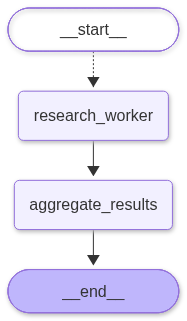

In [38]:
research_graph